## Tasks 1-3: Data Loading and Preprocessing
1. Load and inspect the dataset.
2. Resize all images to a common resolution (64x64 for processing efficiency).
3. Convert images to grayscale.

In [2]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive

# Define dataset paths based on structure
BASE_DIR = '/content/drive/MyDrive/Intro to CV/NEU Steel Surface Data'
TRAIN_IMG_DIR = os.path.join(BASE_DIR, 'train_images')
VALID_IMG_DIR = os.path.join(BASE_DIR, 'valid_images')

# Target resolution for fast processing
IMG_SIZE = (64, 64)

def load_and_preprocess(directory):
    images, labels = [], []
    if not os.path.exists(directory):
        print(f"Directory not found: {directory}")
        return np.array(images), np.array(labels)

    for filename in os.listdir(directory):
        if filename.endswith(('.jpg', '.png', '.bmp')):
            # The label is the prefix before '_' (e.g., crazing_10.jpg -> crazing)
            label = filename.split('_')[0]
            img_path = os.path.join(directory, filename)

            # Read as grayscale (Task 3) and resize (Task 2)
            img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
            if img is not None:
                img_resized = cv2.resize(img, IMG_SIZE)
                images.append(img_resized)
                labels.append(label)

    return np.array(images), np.array(labels)

print("Loading training data...")
X_train_raw, y_train_str = load_and_preprocess(TRAIN_IMG_DIR)
print(f"Loaded {len(X_train_raw)} training images.")

print("Loading validation data...")
X_valid_raw, y_valid_str = load_and_preprocess(VALID_IMG_DIR)
print(f"Loaded {len(X_valid_raw)} validation images.")

Loading training data...
Loaded 1700 training images.
Loading validation data...
Loaded 100 validation images.


## Tasks 4-5: HOG Feature Extraction & Visualization
4. Extract HOG features.
5. Visualize the HOG representation of representative images.

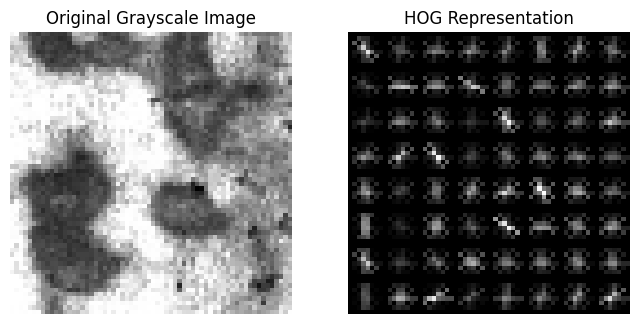

In [3]:
from skimage.feature import hog

# Function to extract HOG features
def extract_hog_features(images, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2)):
    features = []
    for img in images:
        fd = hog(img, orientations=orientations,
                 pixels_per_cell=pixels_per_cell,
                 cells_per_block=cells_per_block,
                 visualize=False)
        features.append(fd)
    return np.array(features)

# Extract features for one image with visualization enabled (Task 5)
if len(X_train_raw) > 0:
    sample_img = X_train_raw[0]
    fd, hog_image = hog(sample_img, orientations=9, pixels_per_cell=(8, 8),
                        cells_per_block=(2, 2), visualize=True)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4), sharex=True, sharey=True)
    ax1.axis('off')
    ax1.imshow(sample_img, cmap=plt.cm.gray)
    ax1.set_title('Original Grayscale Image')

    ax2.axis('off')
    ax2.imshow(hog_image, cmap=plt.cm.gray)
    ax2.set_title('HOG Representation')
    plt.show()

## Tasks 6-7: Classification
6. Train an SVM classifier using HOG features.
7. Train at least one additional machine-learning classifier (XGBoost).

In [4]:
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
import time

# Extract HOG features for the entire dataset
print("Extracting HOG features for training set...")
X_train_hog = extract_hog_features(X_train_raw)
print("Extracting HOG features for validation set...")
X_valid_hog = extract_hog_features(X_valid_raw)

# Encode string labels to integers (required for XGBoost)
le = LabelEncoder()
y_train = le.fit_transform(y_train_str)
y_valid = le.transform(y_valid_str)

# Task 6: Train SVM (using probability=True for Task 13 confidence scores)
print("\nTraining SVM Classifier...")
svm_clf = SVC(kernel='linear', probability=True, random_state=42)
start_time = time.time()
svm_clf.fit(X_train_hog, y_train)
print(f"SVM trained in {time.time() - start_time:.2f} seconds.")

# Task 7: Train XGBoost
print("\nTraining XGBoost Classifier...")
xgb_clf = XGBClassifier(use_label_encoder=False, eval_metric='mlogloss', random_state=42)
start_time = time.time()
xgb_clf.fit(X_train_hog, y_train)
print(f"XGBoost trained in {time.time() - start_time:.2f} seconds.")

Extracting HOG features for training set...
Extracting HOG features for validation set...

Training SVM Classifier...
SVM trained in 7.94 seconds.

Training XGBoost Classifier...


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [04:53:07] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost trained in 117.77 seconds.


## Tasks 8-10: Classifier Evaluation
8. Compare the performance of the classifiers.
9. Generate a confusion matrix and classification report.
10. Calculate accuracy, precision, recall, and F1-score.

,Metric,SVM,XGBoost
0,Accuracy,0.7600,0.8200
1,Precision (Weighted),0.7734,0.8249
2,Recall (Weighted),0.7600,0.8200
3,F1-Score (Weighted),0.7532,0.8200



SVM CLASSIFICATION REPORT
              precision    recall  f1-score   support

     crazing       0.75      0.88      0.81        17
   inclusion       0.58      0.82      0.68        17
     patches       0.92      0.69      0.79        16
      pitted       0.70      0.41      0.52        17
   rolled-in       0.89      0.94      0.91        17
   scratches       0.81      0.81      0.81        16

    accuracy                           0.76       100
   macro avg       0.78      0.76      0.75       100
weighted avg       0.77      0.76      0.75       100


XGBOOST CLASSIFICATION REPORT
              precision    recall  f1-score   support

     crazing       0.71      0.71      0.71        17
   inclusion       0.76      0.94      0.84        17
     patches       0.93      0.81      0.87        16
      pitted       0.75      0.71      0.73        17
   rolled-in       0.88      0.88      0.88        17
   scratches       0.93      0.88      0.90        16

    accuracy       

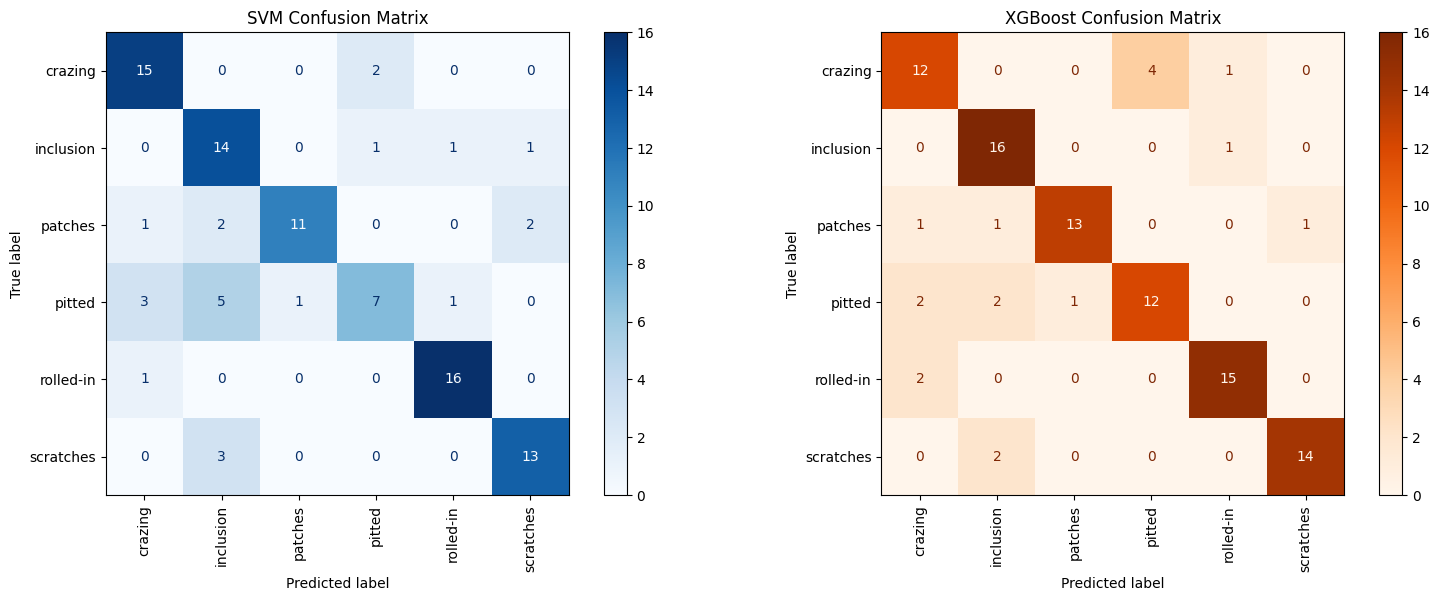

In [5]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# Predictions
y_pred_svm = svm_clf.predict(X_valid_hog)
y_pred_xgb = xgb_clf.predict(X_valid_hog)

# Calculate Metrics function
def get_metrics(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='weighted')
    rec = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')
    return [acc, prec, rec, f1]

# Tabular Comparison (Tasks 8, 10)
metrics_data = {
    'Metric': ['Accuracy', 'Precision (Weighted)', 'Recall (Weighted)', 'F1-Score (Weighted)'],
    'SVM': get_metrics(y_valid, y_pred_svm),
    'XGBoost': get_metrics(y_valid, y_pred_xgb)
}
df_metrics = pd.DataFrame(metrics_data)
display(df_metrics.round(4))

# Classification Reports (Task 9)
print("\n" + "="*50)
print("SVM CLASSIFICATION REPORT")
print("="*50)
print(classification_report(y_valid, y_pred_svm, target_names=le.classes_))

print("\n" + "="*50)
print("XGBOOST CLASSIFICATION REPORT")
print("="*50)
print(classification_report(y_valid, y_pred_xgb, target_names=le.classes_))

# Separate Confusion Matrices (Task 9)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

ConfusionMatrixDisplay.from_predictions(y_valid, y_pred_svm, display_labels=le.classes_,
                                        xticks_rotation='vertical', ax=ax1, cmap='Blues')
ax1.set_title("SVM Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(y_valid, y_pred_xgb, display_labels=le.classes_,
                                        xticks_rotation='vertical', ax=ax2, cmap='Oranges')
ax2.set_title("XGBoost Confusion Matrix")

plt.tight_layout()
plt.show()

## Task 11: HOG Parameters Experiment
Investigate the effect of different HOG parameters, including cell size and number of orientations.
Comparing:
*   Cell sizes: 4x4, 8x8, 16x16
*   Orientations: 6, 9, 12

In [6]:
# Defined search space
cell_sizes = [(4, 4), (8, 8), (16, 16)]
orientations_list = [6, 9, 12]

results = []

# Using SVM for quick experimental iterations
for cells in cell_sizes:
    for ori in orientations_list:
        print(f"Testing HOG Params - Cells: {cells}, Orientations: {ori}...")

        # Extract features
        X_train_exp = extract_hog_features(X_train_raw, orientations=ori, pixels_per_cell=cells)
        X_valid_exp = extract_hog_features(X_valid_raw, orientations=ori, pixels_per_cell=cells)

        # Train & Evaluate
        clf = SVC(kernel='linear', random_state=42)
        clf.fit(X_train_exp, y_train)
        preds = clf.predict(X_valid_exp)

        acc = accuracy_score(y_valid, preds)
        f1 = f1_score(y_valid, preds, average='weighted')

        results.append({
            'Cell Size': f"{cells[0]}x{cells[1]}",
            'Orientations': ori,
            'Accuracy': acc,
            'F1-Score': f1
        })

df_hog_exp = pd.DataFrame(results)
display(df_hog_exp.sort_values(by='F1-Score', ascending=False).round(4))

Testing HOG Params - Cells: (4, 4), Orientations: 6...
Testing HOG Params - Cells: (4, 4), Orientations: 9...
Testing HOG Params - Cells: (4, 4), Orientations: 12...
Testing HOG Params - Cells: (8, 8), Orientations: 6...
Testing HOG Params - Cells: (8, 8), Orientations: 9...
Testing HOG Params - Cells: (8, 8), Orientations: 12...
Testing HOG Params - Cells: (16, 16), Orientations: 6...
Testing HOG Params - Cells: (16, 16), Orientations: 9...
Testing HOG Params - Cells: (16, 16), Orientations: 12...


,Cell Size,Orientations,Accuracy,F1-Score
7,16x16,9,0.87,0.8623
8,16x16,12,0.87,0.8560
6,16x16,6,0.83,0.8211
3,8x8,6,0.82,0.8209
2,4x4,12,0.82,0.8141
5,8x8,12,0.81,0.8068
4,8x8,9,0.76,0.7532
0,4x4,6,0.75,0.7405
1,4x4,9,0.69,0.6864


## Task 12: Robustness Analysis
Evaluate the trained system under realistic imaging conditions (Brightness variation, Gaussian noise, Blur).

In [7]:
from scipy.ndimage import gaussian_filter

def add_gaussian_noise(image):
    row, col = image.shape
    mean, var = 0, 400
    sigma = var ** 0.5
    gauss = np.random.normal(mean, sigma, (row, col))
    noisy = np.clip(image + gauss, 0, 255)
    return noisy.astype(np.uint8)

def change_brightness(image, factor=1.5):
    img_float = image.astype(np.float32) * factor
    return np.clip(img_float, 0, 255).astype(np.uint8)

def apply_blur(image):
    return gaussian_filter(image, sigma=2)

# Baseline metrics using our initial trained XGBoost
baseline_acc = accuracy_score(y_valid, y_pred_xgb)
baseline_f1 = f1_score(y_valid, y_pred_xgb, average='weighted')

robustness_results = [{'Condition': 'Baseline (No degradation)', 'Accuracy': baseline_acc, 'F1-Score': baseline_f1}]

conditions = {
    'Gaussian Noise': add_gaussian_noise,
    'Brightness (+50%)': change_brightness,
    'Blur (Sigma=2)': apply_blur
}

for name, func in conditions.items():
    # Apply degradation to validation set
    X_valid_degraded = [func(img) for img in X_valid_raw]

    # Extract features
    X_valid_degraded_hog = extract_hog_features(X_valid_degraded)

    # Predict using the initially trained XGBoost model
    preds = xgb_clf.predict(X_valid_degraded_hog)

    acc = accuracy_score(y_valid, preds)
    f1 = f1_score(y_valid, preds, average='weighted')

    robustness_results.append({
        'Condition': name,
        'Accuracy': acc,
        'F1-Score': f1
    })

df_robustness = pd.DataFrame(robustness_results)
df_robustness['Accuracy Drop'] = baseline_acc - df_robustness['Accuracy']
df_robustness['F1 Drop'] = baseline_f1 - df_robustness['F1-Score']
display(df_robustness.round(4))

,Condition,Accuracy,F1-Score,Accuracy Drop,F1 Drop
0,Baseline (No degradation),0.82,0.8200,0.00,0.0000
1,Gaussian Noise,0.23,0.1452,0.59,0.6748
2,Brightness (+50%),0.60,0.5935,0.22,0.2265
3,Blur (Sigma=2),0.20,0.0975,0.62,0.7225


## Task 13: Industrial Quality-Control Output
Final module decision block according to required output constraints.

PRODUCT INSPECTION RESULT
Prediction: DEFECTIVE (crazing)
Confidence: 92.45%
Action: REJECT PRODUCT


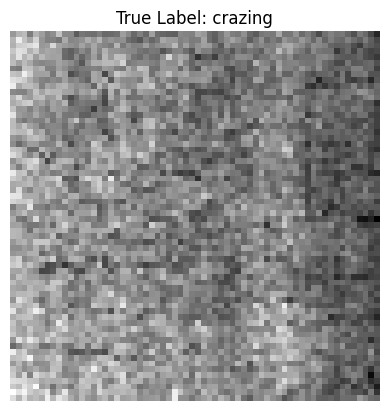

In [8]:
def inspect_product(image_index, model=xgb_clf, le=le):
    if len(X_valid_raw) == 0:
        return "No validation images loaded."

    # Get image and extract feature (using validation set as proxy for new products)
    img = X_valid_raw[image_index]
    actual_label = y_valid_str[image_index]

    # Extract HOG for this single image
    fd = extract_hog_features([img])

    # Prediction and confidence
    pred_idx = model.predict(fd)[0]
    pred_probs = model.predict_proba(fd)[0]
    confidence = pred_probs[pred_idx] * 100

    predicted_class = le.inverse_transform([pred_idx])[0]

    # Logic: Since all dataset classes (crazing, inclusion, patches, pitted_surface, rolled-in_scale, scratches)
    # are forms of defects, predicting any of them confidently means the product is DEFECTIVE.
    # We will assume a product is strictly NON-DEFECTIVE only if confidence is heavily split/low
    # (or if you train a specific 'Normal' class later). For this dataset, they are all defects.

    if confidence > 50:
        status = "DEFECTIVE"
        action = "REJECT PRODUCT"
    else:
        status = "NON-DEFECTIVE"
        action = "ACCEPT PRODUCT"

    # Display Result matching the exact required PDF format
    print("PRODUCT INSPECTION RESULT")
    print(f"Prediction: {status} ({predicted_class})")
    print(f"Confidence: {confidence:.2f}%")
    print(f"Action: {action}")

    # Show the image for context
    plt.imshow(img, cmap='gray')
    plt.title(f"True Label: {actual_label}")
    plt.axis('off')
    plt.show()

# Test the module on the first validation image
inspect_product(0)